In [2]:
import pandas as pd
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
missing_data = df.isnull().sum()
print("Here are the missing values in each column :")
print(missing_data)

Here are the missing values in each column :
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [4]:
df = df.drop(columns=['Cabin'])
average_age = df['Age'].mean()
df['Age'] = df['Age'].fillna(average_age)
df = df.dropna(subset=['Embarked'])
print("Missing Values after cleaning:")
print(df.isnull().sum())

Missing Values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [5]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows found :",duplicate_count)
df = df.drop_duplicates()
print("\nOur data types:")
print(df.dtypes)

Number of duplicate rows found : 0

Our data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked        object
dtype: object


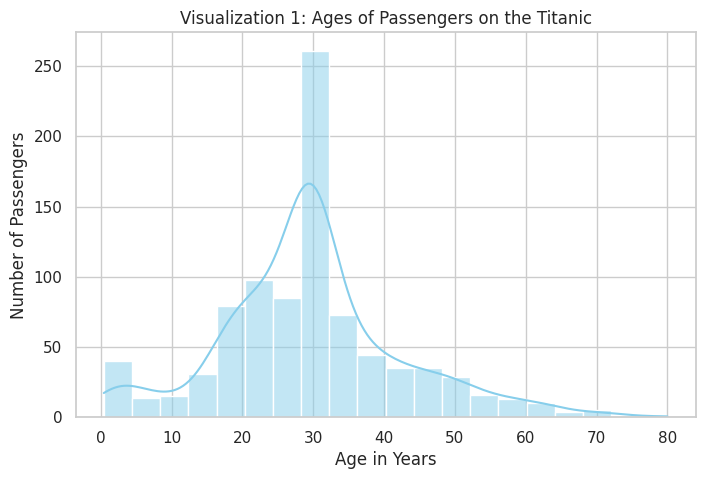

In [6]:
# Bring in our drawing tools (paintbrushes and canvas)
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style to make our graphs look professional and pretty
sns.set_theme(style="whitegrid")

# Let's create Visualization 1: A Histogram of Passenger Ages
plt.figure(figsize=(8, 5)) # This sets the size of our canvas (8 inches wide, 5 inches tall)

# Draw the histogram. 'bins=20' means we group the ages into 20 columns.
sns.histplot(df['Age'], bins=20, color='skyblue', kde=True)

# Add a title and labels so people know what they are looking at
plt.title('Visualization 1: Ages of Passengers on the Titanic')
plt.xlabel('Age in Years')
plt.ylabel('Number of Passengers')

# Tell Python to show us the final drawing!
plt.show()

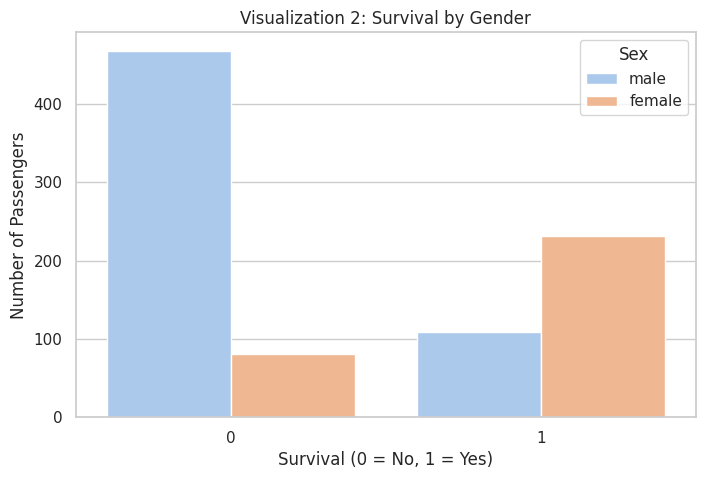

In [7]:
# Set the size of our canvas again
plt.figure(figsize=(8, 5))

# Draw a count plot.
# x='Survived' puts Survival on the bottom (0 = Did not survive, 1 = Survived).
# hue='Sex' tells Python to split the bars by gender (male and female).
sns.countplot(data=df, x='Survived', hue='Sex', palette='pastel')

# Add our title and labels
plt.title('Visualization 2: Survival by Gender')
plt.xlabel('Survival (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

# Show the drawing!
plt.show()

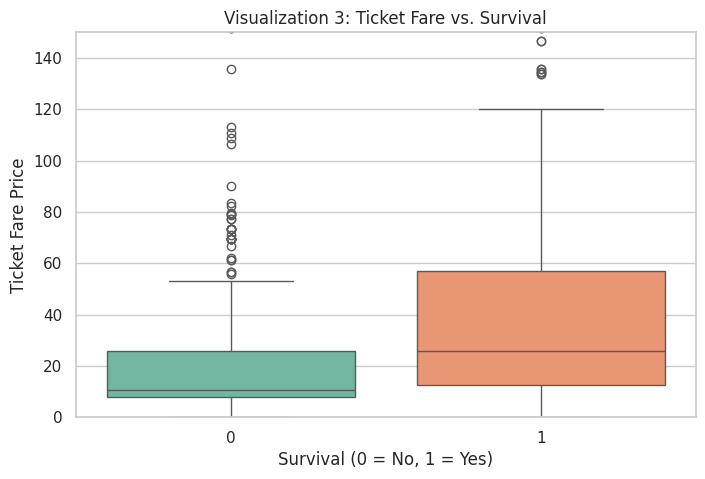

In [9]:
plt.figure(figsize=(8, 5))

# Draw the boxplot with hue assigned to 'Survived' to prevent the deprecation warning
sns.boxplot(data=df, x='Survived', y='Fare', hue='Survived', palette='Set2', legend=False)

# Limit the y-axis to $150 to keep the boxes readable
plt.ylim(0, 150)

plt.title('Visualization 3: Ticket Fare vs. Survival')
plt.xlabel('Survival (0 = No, 1 = Yes)')
plt.ylabel('Ticket Fare Price')

plt.show()